In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = np.loadtxt("wdbc.data", delimiter=",", dtype=str)
print(data.shape)
rng = np.random.default_rng(seed=42)
rng.shuffle(data)
data


(569, 32)


array([['913512', 'B', '11.68', ..., '0.09815', '0.2804', '0.08024'],
       ['888264', 'M', '17.35', ..., '0.08235', '0.2452', '0.06515'],
       ['8813129', 'B', '13.27', ..., '0.09678', '0.2506', '0.07623'],
       ...,
       ['91813701', 'B', '13.46', ..., '0.1427', '0.3518', '0.08665'],
       ['869104', 'M', '16.11', ..., '0.1216', '0.2792', '0.08158'],
       ['923169', 'B', '9.683', ..., '0.03846', '0.2552', '0.0792']],
      dtype='<U9')

Class 1 is malignant. Class 2 is benign

In [3]:
X = data[:500,2:].astype(float)
T = (data[:500,1]=='M').astype(int)

In [4]:
X.shape

(500, 30)

In [5]:
X

array([[1.168e+01, 1.617e+01, 7.549e+01, ..., 9.815e-02, 2.804e-01,
        8.024e-02],
       [1.735e+01, 2.306e+01, 1.110e+02, ..., 8.235e-02, 2.452e-01,
        6.515e-02],
       [1.327e+01, 1.702e+01, 8.455e+01, ..., 9.678e-02, 2.506e-01,
        7.623e-02],
       ...,
       [1.356e+01, 1.390e+01, 8.859e+01, ..., 9.090e-02, 3.065e-01,
        8.177e-02],
       [1.464e+01, 1.685e+01, 9.421e+01, ..., 7.828e-02, 2.455e-01,
        6.596e-02],
       [1.163e+01, 2.929e+01, 7.487e+01, ..., 6.835e-02, 2.884e-01,
        7.220e-02]])

In [6]:
T.shape

(500,)

In [7]:
#Data normalization
mean = np.mean(X,axis=0)
std = np.std(X,axis=0)
X = (X-mean)/std

Using a second order polynomial basis function for our data

In [8]:
phi = []; #2nd order polynomial estimate
for xn in X:
    phi_n = [1]
    for i in range(X.shape[1]):
        phi_n.append(xn[i])
    for i in range(X.shape[1]):
        for j in range(i,X.shape[1]):
            phi_n.append(xn[i]*xn[j])
    phi.append(phi_n)
phi = np.array(phi)
phi.shape

(500, 496)

In [9]:
w = np.zeros((phi.shape[1],1))


In [10]:
def sigmoid(a):
    e = np.exp(-np.abs(a))
    return np.where(a >= 0, 1 / (1 + e), e / (1 + e))

Here $\mathbf{T}$ denotes a vector containing target values $t_1,...,t_n$ and $\mathbf{x}$ denotes the input data vector $\mathbf{x_1},..., \mathbf{x_n}$. Note that t $\in \set{0,1}$ $y_n$ means $\sigma\!\left(\mathbf{w}^{T}\boldsymbol{\phi}(\mathbf{x_n})\right)$ $\phi(\mathbf{x})$ means our basis function applied to our input vector. We train using iterative reweighted least squares


$$
p(C_1 \mid \mathbf{x}, \mathbf{w})
= \sigma\!\left(\mathbf{w}^{T}\boldsymbol{\phi}(\mathbf{x})\right)
= y
= p(t=1 \mid \mathbf{x}, \mathbf{w})
$$

$$
p(t \mid \mathbf{x}, \mathbf{w})
= y^{t}(1-y)^{1-t}
$$

$$
p(\mathbf{T} \mid X, \mathbf{w})
= \prod_{n=1}^{N} p(t_n \mid \mathbf{x}_n, \mathbf{w})
$$

$$
p(\mathbf{T} \mid X, \mathbf{w})
= \prod_{n=1}^{N} y_n^{t_n}(1-y_n)^{1-t_n}
$$

$$
-\ln p(\mathbf{T} \mid X, \mathbf{w})
= -\sum_{n=1}^{N}
\left[
t_n \ln y_n + (1-t_n)\ln(1-y_n)
\right]
$$

$$
E(\mathbf{w})
= -\sum_{n=1}^{N}
\left[
t_n \ln y_n + (1-t_n)\ln(1-y_n)
\right]
$$

$$
\nabla_{\mathbf{w}} E(\mathbf{w})
= \sum_{n=1}^{N} (y_n-t_n)\boldsymbol{\phi}(\mathbf{x}_n)
$$

$$
\mathbf{H}
= \nabla_{\mathbf{w}}\nabla_{\mathbf{w}}^{T} E(\mathbf{w})
= \sum_{n=1}^{N} y_n(1-y_n)
\boldsymbol{\phi}(\mathbf{x}_n)\boldsymbol{\phi}(\mathbf{x}_n)^{T}
$$

$$
\mathbf{w}^{\mathrm{new}}
= \mathbf{w}^{\mathrm{old}}
- \mathbf{H}^{-1}\nabla_{\mathbf{w}} E(\mathbf{w}) 
$$

In [11]:
#IRLS
iterations = 0
tol = 1e-6

while(iterations <30):
    old_error = 0
    grad = np.zeros((phi.shape[1],1))
    hessian = np.zeros((phi.shape[1],phi.shape[1]))
    for n in range(phi.shape[0]):
        phi_n = phi[n].reshape((phi.shape[1],1))
        yn = sigmoid(w.T@phi_n)
        grad+= (yn-T[n])*phi_n
        hessian+=yn*(1-yn)*phi_n@phi_n.T
       
    update = 0
    try:
        update = np.linalg.inv(hessian)@grad
    except np.linalg.LinAlgError:
        update = np.linalg.pinv(hessian)@grad
    if(np.linalg.norm(grad)<tol): #I stop when the norm of the gradient is close to zero
        print("Stopping early")
        break
    w_ = w - update
        
    iterations+=1
    print(f"{iterations} completed")
    w =w_    

1 completed
2 completed
3 completed
4 completed
5 completed
6 completed
7 completed
8 completed
9 completed
10 completed
11 completed
12 completed
13 completed
14 completed
15 completed
16 completed
17 completed
18 completed
19 completed
20 completed
21 completed
Stopping early


In [12]:
w

array([[-6.78939709e+01],
       [ 1.99647256e+01],
       [-1.20638624e+01],
       [ 1.83272696e+02],
       [-1.49532266e+02],
       [-5.74051472e+01],
       [ 3.28097651e+01],
       [-4.21571689e+01],
       [ 6.35716281e+01],
       [-1.18082186e+01],
       [ 8.05844490e+00],
       [-3.46181372e+02],
       [-1.62122211e+00],
       [ 1.94867258e+02],
       [ 4.08162107e+02],
       [-2.81467284e+01],
       [-1.32857417e+01],
       [-8.92354038e+01],
       [-4.48369257e+00],
       [ 9.10174924e+00],
       [ 4.69867558e+00],
       [ 7.30719263e+02],
       [ 2.95200873e+01],
       [-4.14058331e+02],
       [-6.73712812e+02],
       [ 4.66366450e+01],
       [-1.58685517e+01],
       [ 1.00546370e+02],
       [-1.05040108e+01],
       [ 2.69824535e+00],
       [-4.24207861e+01],
       [-2.97441647e+04],
       [ 2.33914223e+03],
       [ 3.97826528e+04],
       [ 1.82929331e+04],
       [-1.04760899e+03],
       [ 2.24262975e+01],
       [-3.58273927e+03],
       [-1.5

In [13]:
test_x = data[500:,2:].astype(float)
test_t = (data[500:,1]=='M').astype(int)
test_x = (test_x-mean)/std

In [14]:
phi_test = []; 
for xn in test_x:
    phi_n = [1]
    for i in range(test_x.shape[1]):
        phi_n.append(xn[i])
    for i in range(test_x.shape[1]):
        for j in range(i,test_x.shape[1]):
            phi_n.append(xn[i]*xn[j])
    phi_test.append(phi_n)
phi_test = np.array(phi_test)
phi_test.shape

(69, 496)

In [15]:
w.shape

(496, 1)

In [16]:
total_patterns = phi_test.shape[0]
misclassified = 0
for n in range(phi_test.shape[0]):
    yn = sigmoid(w.T@(phi_test[n].reshape((phi_test.shape[1],1))))
    res = 1
    if(yn>=0.5):
        res = 1
    else:
        res = 0;
    misclassified+= abs(test_t[n] - res)
print("Error:",(misclassified/total_patterns)*100,"%")
              

Error: 43.47826086956522 %


I am going to approximate my posterior distribution to be a gaussian using the laplace approximation. Therefore im using a gaussian prior
For any general Gaussian Prior we have:

$$
p(\mathbf{w})
= \mathcal{N}(\mathbf{w}\mid\mathbf{m}_0,\mathbf{S}_0)
$$

$$
p(\mathbf{w}\mid\mathbf{T})
\propto p(\mathbf{T}\mid\mathbf{w})p(\mathbf{w})
$$

$$
-\ln p(\mathbf{w}\mid\mathbf{T})
=
-\sum_{n=1}^{N}
\left[t_n\ln y_n+(1-t_n)\ln(1-y_n)\right]
+\frac{1}{2}(\mathbf{w}-\mathbf{m}_0)^T
\mathbf{S}_0^{-1}(\mathbf{w}-\mathbf{m}_0)
+\text{const}
$$

$$
-\nabla_{\mathbf{w}}\ln p(\mathbf{w}\mid\mathbf{T})
=
\sum_{n=1}^{N}(y_n-t_n)\boldsymbol{\phi}(\mathbf{x}_n)
+\mathbf{S}_0^{-1}(\mathbf{w}-\mathbf{m}_0)
$$

$$
-\nabla_{\mathbf{w}}\nabla_{\mathbf{w}}^T
\ln p(\mathbf{w}\mid\mathbf{T})
=
\sum_{n=1}^{N}y_n(1-y_n)
\boldsymbol{\phi}(\mathbf{x}_n)\boldsymbol{\phi}(\mathbf{x}_n)^T
+\mathbf{S}_0^{-1}
$$
The laplace approximation approximates a probability density as a gaussian which is centred at its mode. 
$$
p(\mathbf{w}\mid\mathbf{T})
\approx q(\mathbf{w})
=
\mathcal{N}(\mathbf{w}\mid\mathbf{w}_{\mathrm{MAP}},\mathbf{S}_N)
$$

$$
\mathbf{S}_N^{-1}
=
\left.
\left[
\sum_{n=1}^{N}y_n(1-y_n)
\boldsymbol{\phi}(\mathbf{x}_n)\boldsymbol{\phi}(\mathbf{x}_n)^T
+\mathbf{S}_0^{-1}
\right]
\right|_{\mathbf{w}=\mathbf{w}_{\mathrm{MAP}}}
$$

I have taken my prior to be a zero mean gaussian with covariance matrix $\alpha^{-1}I$

$$
\mathbf{S}_0=\alpha^{-1}\mathbf{I}
\quad\Longrightarrow\quad
\mathbf{S}_N
=
\left[
\sum_{n=1}^{N}y_n(1-y_n)
\boldsymbol{\phi}(\mathbf{x}_n)\boldsymbol{\phi}(\mathbf{x}_n)^T
+\alpha\mathbf{I}
\right]_{\mathbf{w}=\mathbf{w}_{\mathrm{MAP}}}^{-1}
$$

$\mathbf{w}_{\mathrm{MAP}}$ can be calculated using IRLS using the above formulas for the gradient and hessian.

In [17]:
#Posterior Distribution
wmap = np.zeros((phi.shape[1],1))
iterations = 0
alpha = 0.02
while(iterations < 30):
    grad = np.zeros((phi.shape[1],1))
    hessian = np.zeros((phi.shape[1],phi.shape[1]))
    for n in range(phi.shape[0]):
        phi_n = phi[n].reshape((phi.shape[1],1))
        yn = sigmoid(wmap.T@phi_n)
        grad+= (yn-T[n])*phi_n
        hessian+=yn*(1-yn)*phi_n@phi_n.T
    update = 0
    grad+=alpha*wmap
    hessian+=alpha*np.identity(phi.shape[1])
    try:
        update = np.linalg.inv(hessian)@grad
    except np.linalg.LinAlgError:
        update = np.linalg.pinv(hessian)@grad
    if(np.linalg.norm(grad)<tol):
        print("Stopping early")
        break
    wmap = wmap - update
    
    iterations+=1
    print(f"{iterations} completed")

1 completed
2 completed
3 completed
4 completed
5 completed
6 completed
7 completed
8 completed
9 completed
10 completed
11 completed
12 completed
13 completed
14 completed
15 completed
16 completed
17 completed
Stopping early


In [18]:
wmap

array([[-1.34638633e+00],
       [ 8.63240764e-01],
       [ 1.21557455e+00],
       [ 9.05857509e-01],
       [ 1.10313833e+00],
       [ 8.58226349e-01],
       [-4.75407095e-01],
       [ 1.45966111e+00],
       [ 1.12122114e+00],
       [-2.32933087e-01],
       [-8.36838367e-01],
       [ 1.63762813e+00],
       [-6.18763027e-01],
       [ 8.28656178e-01],
       [ 1.75161256e+00],
       [ 1.54955717e-01],
       [-1.53023132e+00],
       [ 3.44755147e-01],
       [-2.70187462e-01],
       [-1.15976881e+00],
       [-1.82138216e+00],
       [ 2.03633425e+00],
       [ 2.74994234e+00],
       [ 1.92141402e+00],
       [ 2.16296714e+00],
       [ 2.33370695e+00],
       [ 3.28324708e-02],
       [ 1.79694612e+00],
       [ 1.66392847e+00],
       [ 7.65157457e-01],
       [-6.88407530e-02],
       [-1.18585961e-01],
       [ 5.38955037e-01],
       [-1.32500442e-01],
       [-3.06702511e-02],
       [ 4.44711014e-02],
       [ 8.54953185e-02],
       [ 1.85521552e-01],
       [ 2.5

Now im going to use the maximum a posteriori for predictions

In [19]:
total_patterns = phi_test.shape[0]
misclassified = 0
for n in range(phi_test.shape[0]):
    yn = sigmoid(wmap.T@(phi_test[n].reshape((phi_test.shape[1],1))))
    res = 1
    if(yn>=0.5):
        res = 1
    else:
        res = 0;
    misclassified+= abs(test_t[n] - res)
print("Error:",(misclassified/total_patterns)*100,"%")
              

Error: 4.3478260869565215 %


In [20]:
#For the calculating the covariance matrix of the posterior
Sn = np.identity(phi.shape[1])*alpha
for n in range(phi.shape[0]):
    phi_n = phi[n].reshape((phi.shape[1],1))
    yn = sigmoid(wmap.T@phi_n)
    Sn+= yn*(1-yn)*phi_n@phi_n.T
Sn = np.linalg.inv(Sn)

In [21]:
Sn

array([[23.68421953, -1.18520402,  2.06372417, ..., -0.85061176,
        -0.71104703, -0.17717101],
       [-1.18520402, 42.37335999,  0.72042778, ...,  0.09789079,
        -0.21411217,  0.42394326],
       [ 2.06372417,  0.72042778, 28.7206403 , ..., -0.16277302,
        -1.64541015, -1.31716658],
       ...,
       [-0.85061176,  0.09789079, -0.16277302, ..., 24.37925475,
        -3.57451953, -1.95274735],
       [-0.71104703, -0.21411217, -1.64541015, ..., -3.57451953,
        37.53476984, -3.01864967],
       [-0.17717101,  0.42394326, -1.31716658, ..., -1.95274735,
        -3.01864967, 34.24330565]])

Now I am going to define the predictive distribution
$$
p(C_1,\mathbf{w}\mid\mathbf{x}',\mathbf{T},\alpha)
=
p(C_1\mid\mathbf{w},\mathbf{x}')
p(\mathbf{w}\mid\mathbf{T},\alpha)
$$

$$
\begin{aligned}
p(C_1\mid\mathbf{x}',\mathbf{T},\alpha)
&=
\int p(C_1\mid\mathbf{w},\mathbf{x}')
p(\mathbf{w}\mid\mathbf{T},\alpha)\,d\mathbf{w}
\\
&\approx
\int \sigma\!\left(\mathbf{w}^{T}\boldsymbol{\phi}(\mathbf{x}')\right)
q(\mathbf{w})\,d\mathbf{w}
\end{aligned}
$$

$$
a=\mathbf{w}^{T}\boldsymbol{\phi}(\mathbf{x}')
$$

$$
\sigma\!\left(\mathbf{w}^{T}\boldsymbol{\phi}(\mathbf{x}')\right)
=
\int
\delta\!\left(a-\mathbf{w}^{T}\boldsymbol{\phi}(\mathbf{x}')\right)
\sigma(a)\,da
$$

$$
\begin{aligned}
p(C_1\mid\mathbf{x}',\mathbf{T},\alpha)
&\approx
\int
\underbrace{
\left[
\int
\delta\!\left(a-\mathbf{w}^{T}\boldsymbol{\phi}(\mathbf{x}')\right)
q(\mathbf{w})\,d\mathbf{w}
\right]
}_{p(a)}
\sigma(a)\,da
\\
&=
\int p(a)\sigma(a)\,da
\end{aligned}
$$
Since $\mathbf{w}$ is gaussian distributed, a linear transformation of $\mathbf{w}$ will also be gaussian distributed. 

$$
\begin{aligned}
\mathbb{E}[a]
&= \int a\,p(a)\,da \\
&= \int
\left[
\int a\,\delta\!\left(a-\mathbf{w}^{T}\boldsymbol{\phi}(\mathbf{x}')\right)\,da
\right]
q(\mathbf{w})\,d\mathbf{w} \\
&= \mathbf{w}_{\mathrm{MAP}}^{T}\boldsymbol{\phi}(\mathbf{x}')
= \mu_a
\end{aligned}
$$

$$
\begin{aligned}
\sigma_a^2
&= \operatorname{Var}[a] \\
&= \int a^2p(a)\,da-\left(\mathbb{E}[a]\right)^2 \\
&= \boldsymbol{\phi}(\mathbf{x}')^{T}
\mathbf{S}_N
\boldsymbol{\phi}(\mathbf{x}')
\end{aligned}
$$

$$
\begin{aligned}
p(C_1\mid\mathbf{x}',\mathbf{T},\alpha)
&\approx \int \sigma(a)p(a)\,da \\
&= \int \sigma(a)\,
\mathcal{N}(a\mid\mu_a,\sigma_a^2)\,da \\
&\approx \sigma\!\left(\kappa(\sigma_a^2)\mu_a\right)
\end{aligned}
$$

The following approximation for the integral of the sigmoid and normal distribution was used: https://math.stackexchange.com/questions/4811655/numerical-approximation-of-expected-value-of-sigmoid-function-w-r-t-gaussian-dis

In [22]:
#Predictive Distribution
total_patterns = phi_test.shape[0]
misclassified = 0
for n in range(phi_test.shape[0]):
    phi_x_ = phi_test[n].reshape((phi_test.shape[1],1))
    var = phi_x_.T@Sn@phi_x_
    mu = wmap.T@phi_x_
    var_ = (1+ (np.pi*var)/8)**(-0.5)
    p = sigmoid(var_*mu)
    print(f"Malignant Probability: {p} Actual Label: {test_t[n]}")
    res = 1
    if(p>=0.5):
        res = 1
    else:
        res = 0;
    misclassified+= abs(test_t[n] - res)
print("Error:",(misclassified/total_patterns)*100,"%")

Malignant Probability: [[0.26915937]] Actual Label: 0
Malignant Probability: [[0.43286581]] Actual Label: 0
Malignant Probability: [[0.2364525]] Actual Label: 0
Malignant Probability: [[0.41907521]] Actual Label: 0
Malignant Probability: [[0.55318981]] Actual Label: 1
Malignant Probability: [[0.27529789]] Actual Label: 0
Malignant Probability: [[0.56209058]] Actual Label: 1
Malignant Probability: [[0.33609657]] Actual Label: 0
Malignant Probability: [[0.3632689]] Actual Label: 0
Malignant Probability: [[0.62250263]] Actual Label: 1
Malignant Probability: [[0.43741387]] Actual Label: 0
Malignant Probability: [[0.44128642]] Actual Label: 0
Malignant Probability: [[0.33369111]] Actual Label: 0
Malignant Probability: [[0.641819]] Actual Label: 1
Malignant Probability: [[0.39423955]] Actual Label: 0
Malignant Probability: [[0.27444107]] Actual Label: 0
Malignant Probability: [[0.58754159]] Actual Label: 0
Malignant Probability: [[0.6670661]] Actual Label: 1
Malignant Probability: [[0.759939

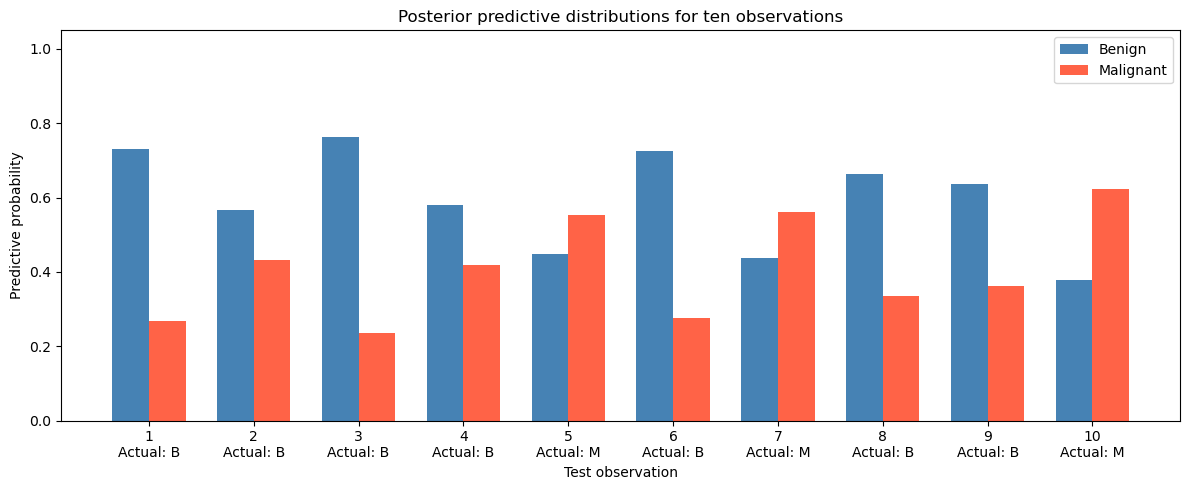

In [23]:
n_obs = 10
p_malignant = np.zeros(n_obs)

for n in range(n_obs):
    phi_x = phi_test[n].reshape(-1, 1)

    mu = (wmap.T @ phi_x).item()
    var = (phi_x.T @ Sn @ phi_x).item()

    kappa = (1 + np.pi * var / 8) ** (-0.5)
    p_malignant[n] = sigmoid(kappa * mu).item()

p_benign = 1 - p_malignant

x = np.arange(n_obs)
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(x - width / 2, p_benign, width,
        label="Benign", color="steelblue")
plt.bar(x + width / 2, p_malignant, width,
        label="Malignant", color="tomato")

labels = [
    f"{n + 1}\nActual: {'M' if test_t[n] == 1 else 'B'}"
    for n in range(n_obs)
]

plt.xticks(x, labels)
plt.ylim(0, 1.05)
plt.xlabel("Test observation")
plt.ylabel("Predictive probability")
plt.title("Posterior predictive distributions for ten observations")
plt.legend()
plt.tight_layout()
plt.show()

Now I'm going to build a probablistically generative model to classify data.  
Here $\mathcal{D}$ means the entire dataset of inputs and labels
$$
p(\mathbf{x}\mid C_1)
= \mathcal{N}(\mathbf{x}\mid\boldsymbol{\mu}_1,\boldsymbol{\Sigma})
$$

$$
p(\mathbf{x}\mid C_2)
= \mathcal{N}(\mathbf{x}\mid\boldsymbol{\mu}_2,\boldsymbol{\Sigma})
$$

$$
p(C_1)=\pi,
\qquad
p(C_2)=1-\pi
$$

$$
\begin{aligned}
p(\mathcal{D}\mid\pi,\boldsymbol{\mu}_1,\boldsymbol{\mu}_2,\boldsymbol{\Sigma})
&=
\prod_{n=1}^{N}
p(\mathbf{x}_n,C_1)^{t_n}
p(\mathbf{x}_n,C_2)^{1-t_n}
\\
&=
\prod_{n=1}^{N}
\left[
\pi\,\mathcal{N}(\mathbf{x}_n\mid\boldsymbol{\mu}_1,\boldsymbol{\Sigma})
\right]^{t_n}
\left[
(1-\pi)\,\mathcal{N}(\mathbf{x}_n\mid\boldsymbol{\mu}_2,\boldsymbol{\Sigma})
\right]^{1-t_n}
\end{aligned}
$$

$$
\begin{aligned}
&-\ln p(\mathcal{D}\mid\pi,\boldsymbol{\mu}_1,\boldsymbol{\mu}_2,\boldsymbol{\Sigma})
\\
&\quad =
-\sum_{n=1}^{N}
\Big[
t_n
\left\{
\ln\pi+
\ln\mathcal{N}(\mathbf{x}_n\mid\boldsymbol{\mu}_1,\boldsymbol{\Sigma})
\right\}
+
(1-t_n)
\left\{
\ln(1-\pi)+
\ln\mathcal{N}(\mathbf{x}_n\mid\boldsymbol{\mu}_2,\boldsymbol{\Sigma})
\right\}
\Big]
\end{aligned}
$$

$$
N_1=\sum_{n=1}^{N}t_n,
\qquad
N_2=\sum_{n=1}^{N}(1-t_n),
\qquad
N=N_1+N_2
$$

Here, $N_1$ and $N_2$ are the numbers of observations in classes $C_1$ and $C_2$, respectively.
Now i will take the gradient of the model wrt to each of its parameters and get the following maximum likelihood solution.
I am using a shared covariance matrix for all the classes

$$
\pi=\frac{N_1}{N}
$$

$$
\boldsymbol{\mu}_1
=\frac{1}{N_1}\sum_{n=1}^{N}t_n\mathbf{x}_n
$$

$$
\boldsymbol{\mu}_2
=\frac{1}{N_2}\sum_{n=1}^{N}(1-t_n)\mathbf{x}_n
$$

$$
\begin{aligned}
\boldsymbol{\Sigma}
=\frac{1}{N}\Bigg[
&\sum_{n=1}^{N}
t_n(\mathbf{x}_n-\boldsymbol{\mu}_1)
(\mathbf{x}_n-\boldsymbol{\mu}_1)^T
\\
&+
\sum_{n=1}^{N}
(1-t_n)(\mathbf{x}_n-\boldsymbol{\mu}_2)
(\mathbf{x}_n-\boldsymbol{\mu}_2)^T
\Bigg]
\end{aligned}
$$

In [24]:
#Generative Model. P(x|C) is a gaussian
pi = 0
for n in range(T.shape[0]):
    if(T[n] == 1):
        pi+=1
pi/=T.shape[0]

mu_1 = np.zeros((X.shape[1],1))
mu_2 = np.zeros((X.shape[1],1))
n1 = 0
n2 = 0
for n in range(X.shape[0]):
    xn = X[n].reshape((X.shape[1],1))
    if(T[n]==1):
        n1+=1
        mu_1+=xn
    else:
        mu_2+=xn
        n2+=1
mu_1/=n1
mu_2/=n2
sigma = np.zeros((X.shape[1],X.shape[1]))
for n in range(X.shape[0]):
    xn = X[n].reshape((X.shape[1],1))
    if(T[n]==1):
        sigma+=(xn-mu_1)@((xn-mu_1).T)
    else:
        sigma+=(xn-mu_2)@((xn - mu_2).T)
sigma*= (1/(n1+n2))

In [25]:
sigma.shape

(30, 30)

In [26]:
def gaussian(mu,cov_matrix,x):
    C = (np.linalg.det(cov_matrix)**(-0.5))*1/((2*np.pi)**(x.shape[0]/2))
    return C*np.exp(-0.5*((x-mu).T@np.linalg.inv(cov_matrix)@(x-mu)))

$$
p(C_1\mid\mathbf{x})
=
\frac{
p(\mathbf{x}\mid C_1)\,p(C_1)
}{
p(\mathbf{x}\mid C_1)\,p(C_1)
+
p(\mathbf{x}\mid C_2)\,p(C_2)
}
$$

In [27]:
total_patterns = test_x.shape[0]
misclassified = 0
for n in range(test_x.shape[0]):
    x = test_x[n].reshape((test_x.shape[1],1))
    p = (gaussian(mu_1,sigma,x)*pi)/(gaussian(mu_1,sigma,x)*pi + (1-pi)*gaussian(mu_2,sigma,x))
    plabel = 0
    if(p>=0.5):
        plabel = 1
    else:
       plabel = 0
    misclassified+= abs(plabel-test_t[n])
print("Error:",(misclassified/total_patterns)*100,"%")

Error: 1.4492753623188406 %
